In [3]:
import jax.numpy as np
import matplotlib.pyplot as plt
from matplotlib.style import use
import jax
use('default')
jax.config.update("jax_enable_x64", True)
plt.rcParams['image.origin'] = 'lower'
import numpy as onp

# latex
import os
os.environ["PATH"] = "/Library/TeX/texbin:" + os.environ["PATH"]
import shutil
print(shutil.which("latex"))

# plt.rcParams.update({
#     "text.usetex": True,
#     "font.family": "serif",
#     "text.latex.preamble": r"""
# \usepackage[T1]{fontenc}
# \usepackage{newtxtext,newtxmath}
# """,

#     "font.size": 10,
#     "axes.labelsize": 10,
#     "axes.titlesize": 10,
#     "xtick.labelsize": 10,
#     "ytick.labelsize": 10,
#     "legend.fontsize": 10,
#     "figure.titlesize": 10,
# })

# plt.rcParams["figure.dpi"] = 300
# # fig_width = 379.41753 / 72.27 # = 5.25
# fig_width = 5.25

# new style
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "text.latex.preamble": r"""
\usepackage[T1]{fontenc}
\usepackage{newtxtext,newtxmath}
""",

    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "legend.title_fontsize": 7,
    "figure.titlesize": 7,

    "figure.dpi": 300,
    "savefig.bbox": None,
})

fig_width = 170 / 25.4  # 6.693 inches

/Library/TeX/texbin/latex


In [4]:
eigvals = np.load('nircam_eigvals.npy')

a0s = np.load('nircam_a0s.npy')

filters = ['f150w2', 'f200w', 'f210m', 'f212n', 'f322w2', 'f444w', 'f480m', 'f470n']

n_ints = 100 # maximum number of integrations

# effective R value
Rs_filts = []

for i in range(len(a0s)):
    
    arr = onp.loadtxt(f'nircam_filts/{filters[i]}.txt')
    wave_m = arr[:, 0] * 1e-6
    throughput = arr[:, 1]
    cutoff = 0.25 * np.max(throughput)
    wlidx = np.where(throughput > cutoff)[0]

    fidx = wlidx[0]
    lidx = wlidx[-1]

    bw = wave_m[lidx] - wave_m[fidx]
    c_wl = (wave_m[lidx] + wave_m[fidx])/2

    Rs_ints = []
    for j in range(n_ints):

        relstd = 1 / (np.abs(a0s[i]) * np.sqrt(eigvals[i] * (j+1)))

        # no. constrained modes
        n_modes = np.argmax(relstd>0.1)

        R = c_wl*n_modes/bw

        Rs_ints.append(R)

    Rs_ints_array = np.array(Rs_ints)
    Rs_filts.append(Rs_ints)

Rs_filts_array = np.array(Rs_filts)

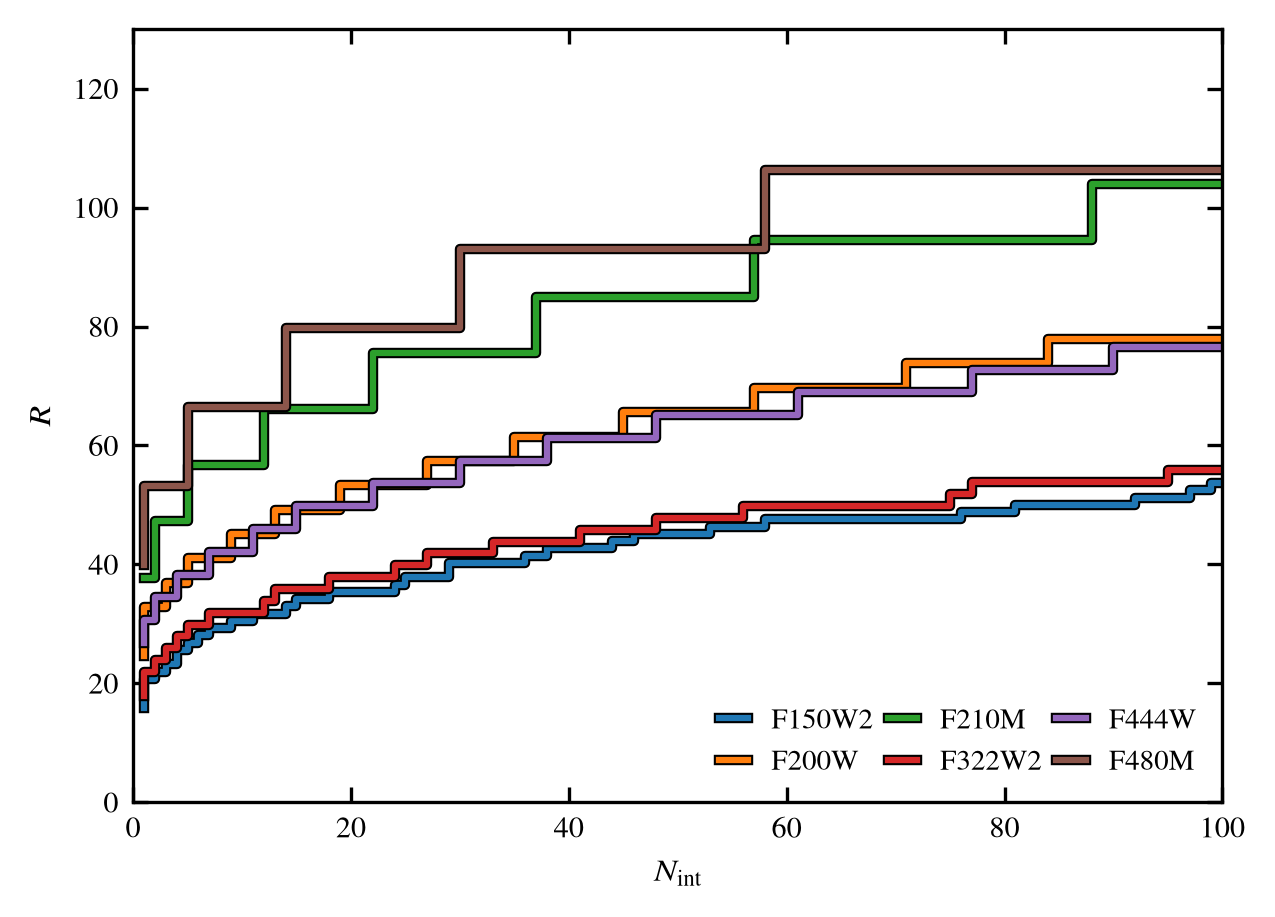

In [5]:
# might make sense to just do 4. nah do 6. gonna need many line styles
import matplotlib.patheffects as pe
path_effects = [pe.Stroke(linewidth=2.5, foreground='k'), pe.Normal()]

plt.figure(figsize=(fig_width*0.7, fig_width/2))
filters_nice = ['F150W2', 'F200W', 'F210M', 'F212N', 'F322W2', 'F444W', 'F480M', 'F470N']
for i in range(3):
    plt.step(np.arange(n_ints)+1, Rs_filts_array[i], label=filters_nice[i], path_effects=path_effects)

for i in np.array([4,5,6]):
    plt.step(np.arange(n_ints)+1, Rs_filts_array[i], label=filters_nice[i], path_effects=path_effects)
    
plt.xlabel(r'$N_{\mathrm{int}}$')
plt.ylabel(r'$R$')
plt.xlim(0, n_ints)
plt.ylim(0,130)

ax = plt.gca()
ax.tick_params('both', direction='in', top=True, right=True)

plt.legend(loc='lower right', ncols=3, handlelength=1.0, frameon=False, columnspacing=0.5)
plt.show()

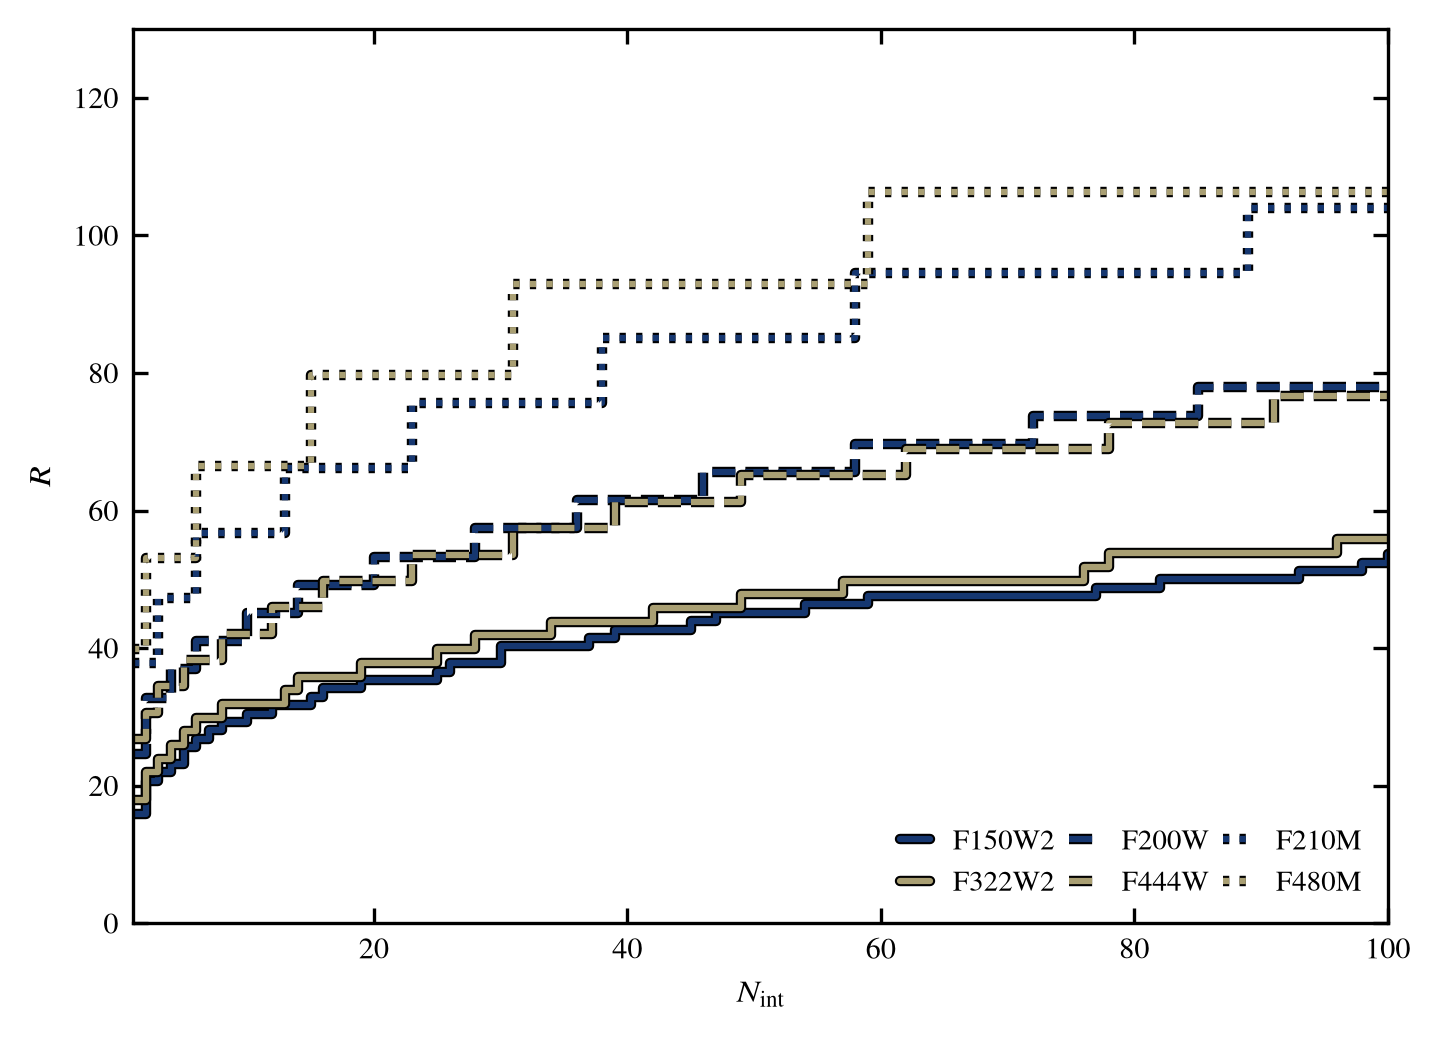

In [6]:
fig, ax = plt.subplots(
    figsize=(fig_width * 0.7, fig_width / 2),
    constrained_layout=True,
)

x = np.arange(1, n_ints + 1)

# Dark and light samples from cividis:
# colourblind-friendly and with clearly different greyscale luminance.
channel_colours = {
    "short": plt.colormaps["cividis"](0.12),
    "long":  plt.colormaps["cividis"](0.68),
}

# Same line style for equivalent bandwidth classes.
line_styles = {
    "W2": "-",   # ultra-wide
    "W":  "--",  # wide
    "M":  ":",  # medium
}

filters = [
    # array index, label, channel, bandwidth class
    (0, "F150W2", "short", "W2"),
    (1, "F200W",  "short", "W"),
    (2, "F210M",  "short", "M"),
    (4, "F322W2", "long",  "W2"),
    (5, "F444W",  "long",  "W"),
    (6, "F480M",  "long",  "M"),
]

lines = {}

import matplotlib.patheffects as pe
path_effects = [pe.Stroke(linewidth=2.5, foreground='k'), pe.Normal()]

for idx, label, channel, bandwidth in filters:
    line, = ax.step(
        x,
        Rs_filts_array[idx],
        where="post",
        label=label,
        color=channel_colours[channel],
        linestyle=line_styles[bandwidth],
        # linewidth=1.6,
        path_effects=path_effects,
        solid_capstyle='round'
    )
    lines[label] = line

ax.set(
    xlabel=r"$N_{\mathrm{int}}$",
    ylabel=r"$R$",
    xlim=(1, n_ints),
    ylim=(0, 130),
)

ax.tick_params(
    axis="both",
    which="both",
    direction="in",
    top=True,
    right=True,
)

# Matplotlib fills a multi-column legend down columns.
# Interleave short/long handles so the displayed rows become:
# F150W2, F200W, F210M
# F322W2, F444W, F480M
legend_order = [
    "F150W2", "F322W2",
    "F200W",  "F444W",
    "F210M",  "F480M",
]

ax.legend(
    [lines[label] for label in legend_order],
    legend_order,
    loc="lower right",
    ncols=3,
    frameon=False,
    handlelength=1.0,     # long enough to see dash-dot clearly
    # handletextpad=0.45,
    columnspacing=0.5,
    # borderaxespad=0.4,
)



plt.show()

In [7]:
eigvals_wfc3 = np.load('wfc3_eigvals.npy')

a0s_wfc3 = np.load('wfc3_a0s.npy')

filters_wfc3 = ['f275w', 'f606w', 'f814w']

n_ints = 100 # maximum number of integrations

# effective R value
Rs_filts_wfc3 = []
Ns_filts_wfc3 = []

for i in range(len(a0s_wfc3)):
    
    arr = onp.loadtxt(f'UVIS/wfc3_uvis2_{filters_wfc3[i]}.txt')
    wave_m = arr[:, 0] * 1e-6
    throughput = arr[:, 1]
    cutoff = 0.25 * np.max(throughput)
    wlidx = np.where(throughput > cutoff)[0]

    fidx = wlidx[0]
    lidx = wlidx[-1]

    bw = wave_m[lidx] - wave_m[fidx]
    c_wl = (wave_m[lidx] + wave_m[fidx])/2

    Rs_ints = []
    Ns_ints = []
    for j in range(n_ints):

        relstd = 1 / (np.abs(a0s_wfc3[i]) * np.sqrt(eigvals_wfc3[i] * (j+1)))

        # no. constrained modes
        n_modes = np.argmax(relstd>0.1)
        # print(n_modes)

        # print(n_modes)
        R = c_wl*n_modes/bw

        Rs_ints.append(R)
        Ns_ints.append(n_modes)

    Rs_ints_array = np.array(Rs_ints)
    Ns_ints_array = np.array(Ns_ints)

    Rs_filts_wfc3.append(Rs_ints)
    Ns_filts_wfc3.append(Ns_ints)

Rs_filts_wfc3_array = np.array(Rs_filts_wfc3)
Ns_filts_wfc3_array = np.array(Ns_filts_wfc3)

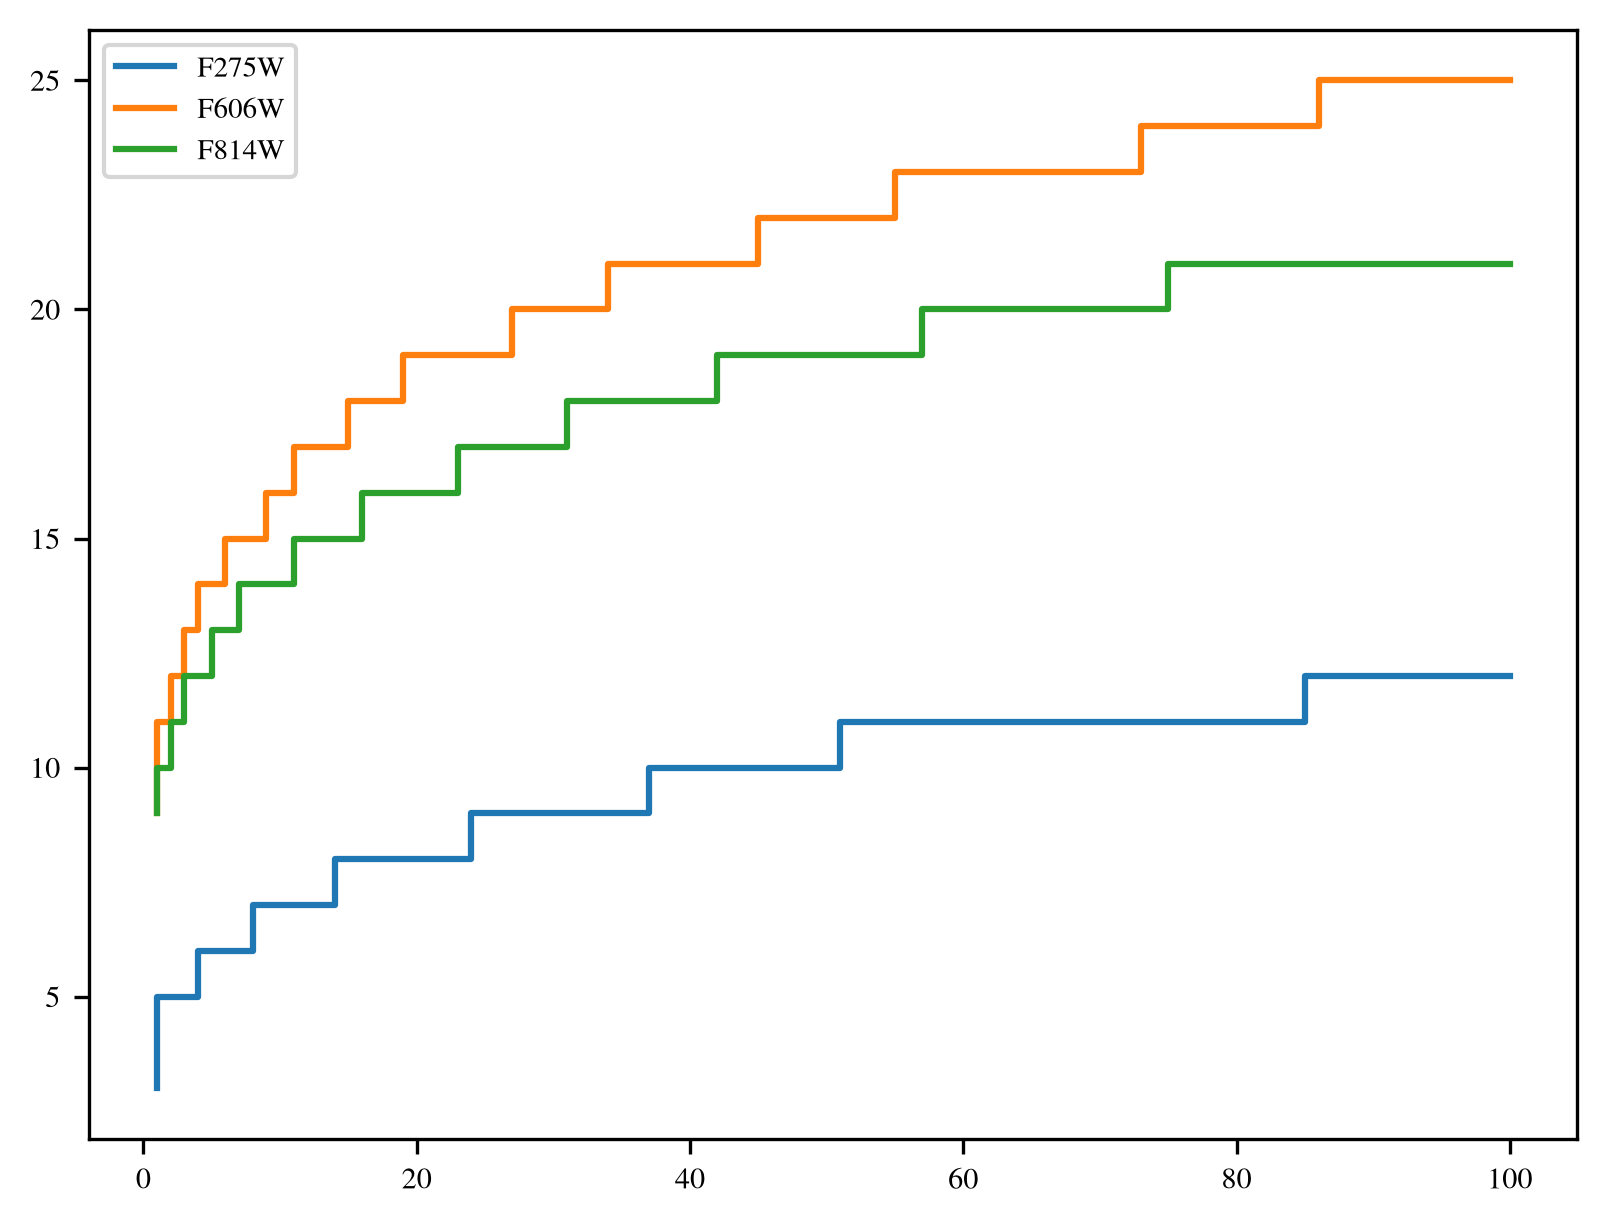

In [8]:
# for i in range(5):
plt.step(x,Ns_filts_wfc3_array[0], label='F275W')
plt.step(x,Ns_filts_wfc3_array[1], label='F606W')
plt.step(x,Ns_filts_wfc3_array[2], label='F814W')


plt.legend()

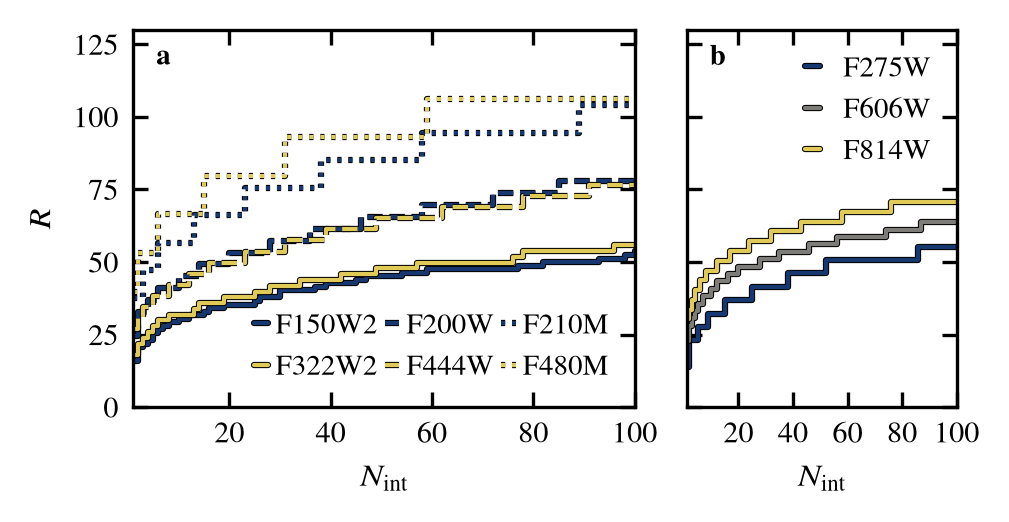

In [20]:
# import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

fig_width_single = 82.5 / 25.4

fig, (ax, ax_wfc3) = plt.subplots(
    1,
    2,
    figsize=(fig_width_single, fig_width_single / 2),
    sharey=True,
    gridspec_kw={
        "width_ratios": [0.65, 0.35],
        "wspace": 0.06,
    },
    constrained_layout=True,
)

x = np.arange(1, n_ints + 1)

# ------------------------------------------------------------------
# Left panel: NIRCam
# ------------------------------------------------------------------

channel_colours = {
    "short": plt.colormaps["cividis"](0.12),
    "long":  plt.colormaps["cividis"](0.88),
}

line_styles = {
    "W2": "-",
    "W":  "--",
    "M":  ":",
}

filters = [
    (0, "F150W2", "short", "W2"),
    (1, "F200W",  "short", "W"),
    (2, "F210M",  "short", "M"),
    (4, "F322W2", "long",  "W2"),
    (5, "F444W",  "long",  "W"),
    (6, "F480M",  "long",  "M"),
]

path_effects = [
    pe.Stroke(linewidth=1.5, foreground="k"),
    pe.Normal(),
]

lines = {}

for idx, label, channel, bandwidth in filters:
    line, = ax.step(
        x,
        Rs_filts_array[idx],
        where="post",
        label=label,
        color=channel_colours[channel],
        linestyle=line_styles[bandwidth],
        path_effects=path_effects,
        solid_capstyle="round",
        lw=1.0,
    )
    lines[label] = line

legend_order = [
    "F150W2", "F322W2",
    "F200W",  "F444W",
    "F210M",  "F480M",
]

ax.legend(
    [lines[label] for label in legend_order],
    legend_order,
    loc="lower right",
    ncols=3,
    frameon=False,
    handlelength=0.5,
    columnspacing=0.25,
    handletextpad=0.25,
)

ax.set_xlabel(r"$N_{\mathrm{int}}$")
ax.set_ylabel(r"$R$")
ax.set_xlim(1, n_ints)
ax.set_ylim(0, 130)

ax.tick_params(
    axis="both",
    which="both",
    direction="in",
    top=True,
    right=True,
)

# adding text
ax.text(
    0.06*5/6.5, 0.96,
    r'\textbf{a}',
    transform=ax.transAxes,
    ha='left',
    va='top',
    color='k'
)

# ------------------------------------------------------------------
# Right panel: WFC3
# ------------------------------------------------------------------

wfc3_filters = [
    (0, "F275W"),
    (1, "F606W"),
    (2, "F814W"),
]

# Well-separated values spanning the useful part of cividis.
wfc3_colours = plt.colormaps["cividis"](
    np.linspace(0.12, 0.88, len(wfc3_filters))
)

for (idx, label), colour in zip(wfc3_filters, wfc3_colours):
    ax_wfc3.step(
        x,
        Rs_filts_wfc3_array[idx],
        where="post",
        label=label,
        color=colour,
        linestyle="-",
        path_effects=path_effects,
        solid_capstyle="round",
        lw=1.0,
    )

ax_wfc3.set_xlabel(r"$N_{\mathrm{int}}$")
ax_wfc3.set_xlim(1, n_ints)

# Shared y-axis, so no duplicate label or tick labels.
ax_wfc3.tick_params(
    axis="both",
    which="both",
    direction="in",
    top=True,
    right=True,
    labelleft=False,
)

ax_wfc3.legend(
    loc="upper right",
    frameon=False,
    handlelength=0.5,
)

# adding text
ax_wfc3.text(
    0.06*5/3.5, 0.96,
    r'\textbf{b}',
    transform=ax_wfc3.transAxes,
    ha='left',
    va='top',
    color='k'
)

ax_wfc3.set_xticks([20, 40, 60, 80, 100])
plt.savefig('filter_Rs_newsize.pdf', dpi=300)
plt.show()